In [124]:
import numpy as np
import scipy
from scipy.stats import beta, boltzmann
from typing import Tuple
import sys
import os
import librosa
import matplotlib.pyplot as plt

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from modules.Pyin import PitchExtractor
from util import audio

pitch_extractor = PitchExtractor()

[-2.9673256e-05 -3.6110661e-05 -3.8504204e-05 ... -3.0914794e-05
 -2.9738290e-05 -3.2249300e-05]


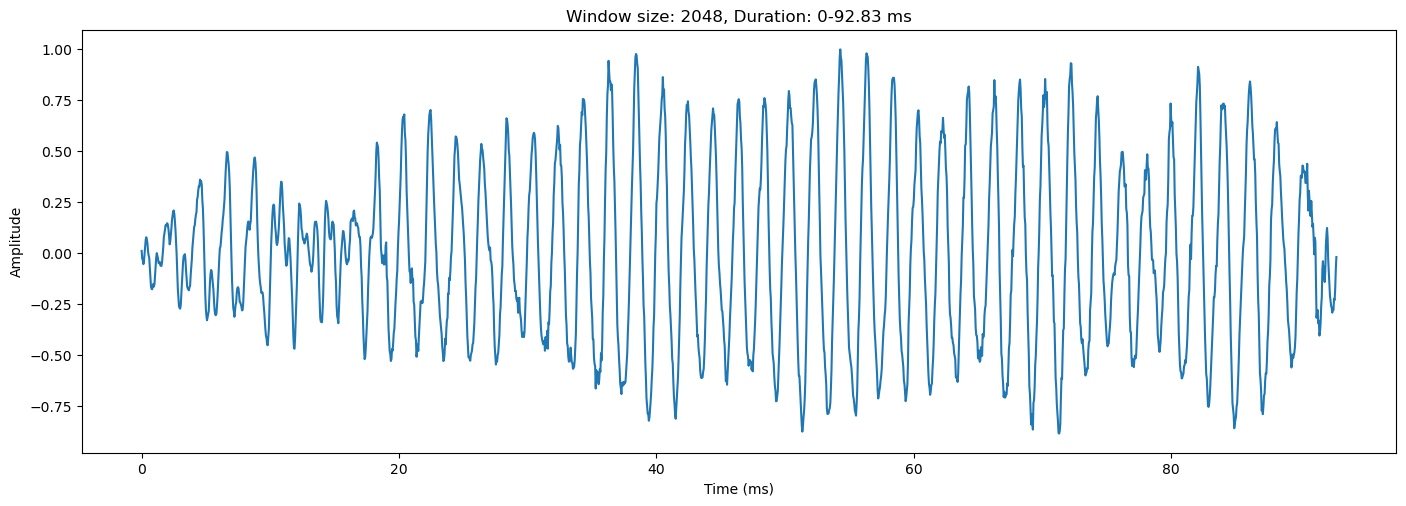

In [125]:
y, sr = librosa.load('./birds_of_feather.wav')
print(y)
windows_size = int(2048)
window_start = np.random.randint(0, len(y) - windows_size)
window_end = window_start + windows_size
window = y[window_start:window_end]
window = window / (np.max(np.abs(window)) + 1e-10) 

time_ms = np.arange(len(window)) * 1000 / sr

plt.figure(figsize=(14, 5))
plt.plot(time_ms, window)

plt.title(f'Window size: {windows_size}, Duration: 0-{time_ms[-1]:.2f} ms')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.tight_layout(pad=0.5) # add padding to avoid overlap
plt.show()

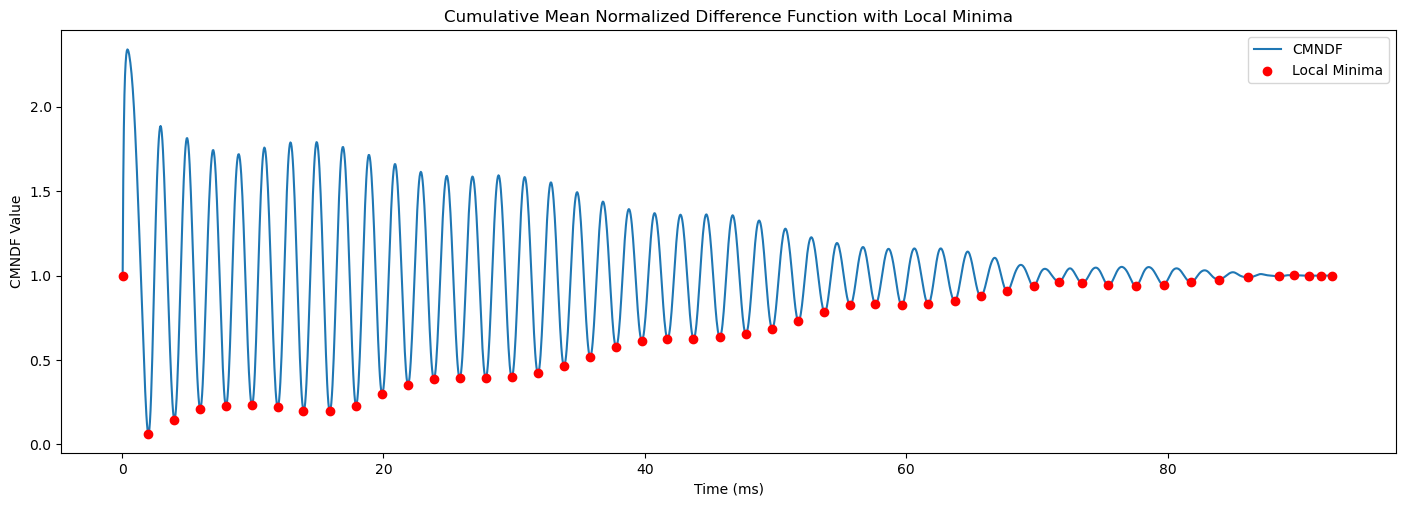

In [126]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[local_minima_index], local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


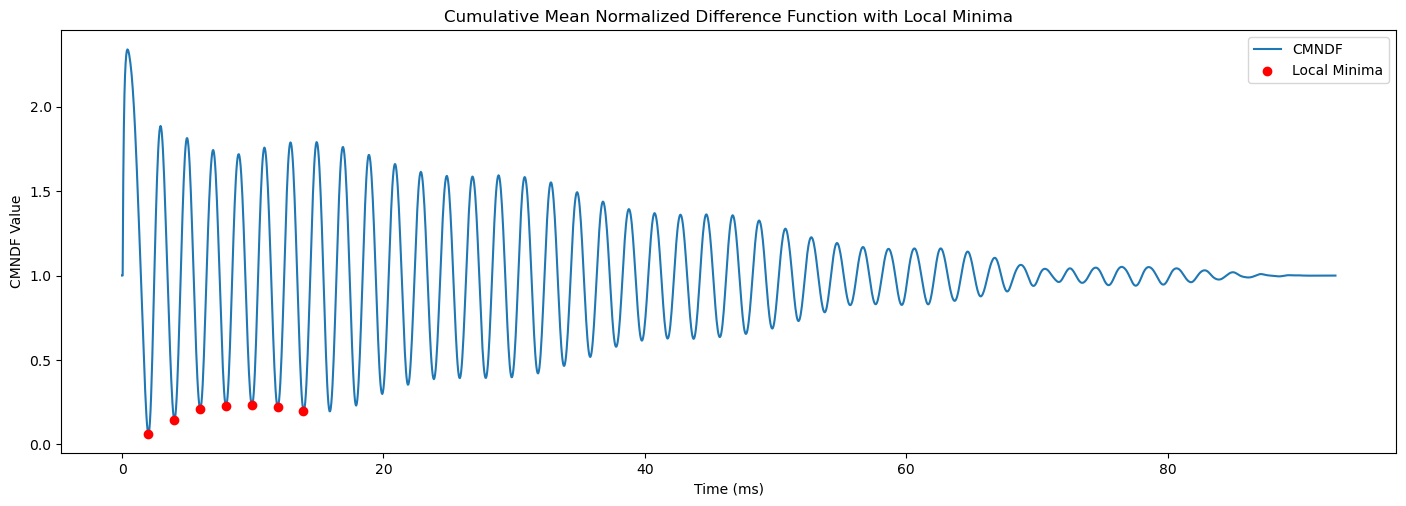

In [127]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
filtered_local_minima, filtered_minima_index = pitch_extractor._filter_local_minimas(local_minima, local_minima_index)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[filtered_minima_index], filtered_local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


[501.13636364 250.56818182 167.04545455 126.         100.68493151
  83.84030418  72.05882353]
[5.90490342e-01 2.72755754e-02 1.08739094e-03 1.21413152e-04
 1.34985903e-05 2.22375944e-06 5.29013707e-07]


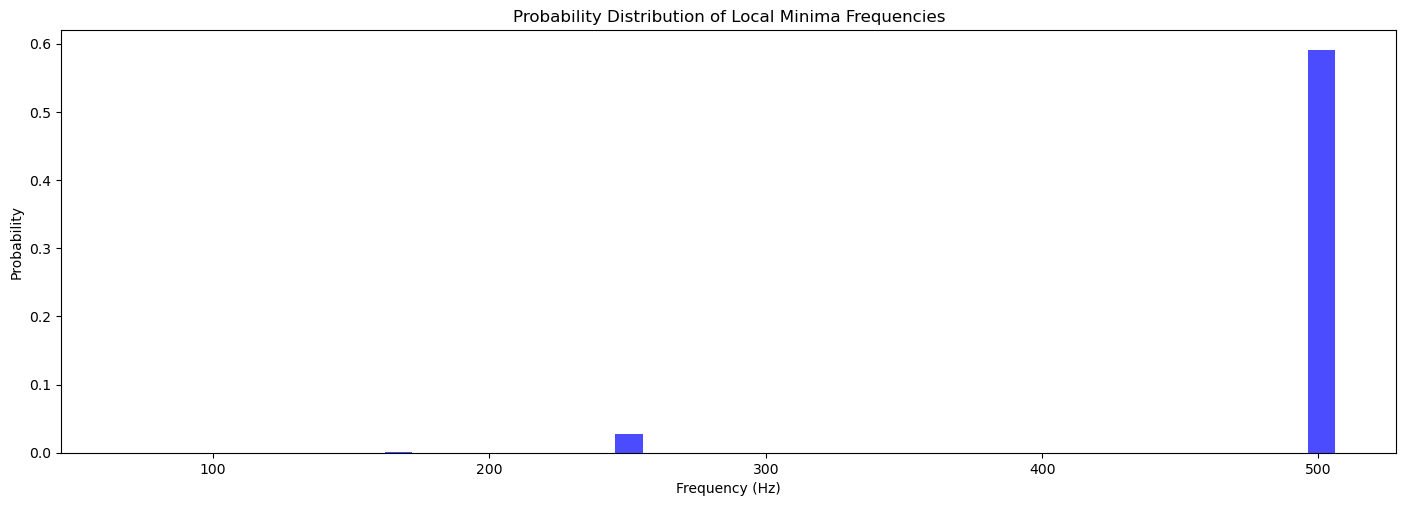

In [128]:
local_minima, local_minima_probs = pitch_extractor._assign_probabilities(filtered_local_minima, filtered_minima_index)
sr = pitch_extractor.sample_rate
local_minima_freqs = sr / filtered_minima_index
print(local_minima_freqs)
print(local_minima_probs)

plt.figure(figsize=(14, 5))
plt.bar(local_minima_freqs, local_minima_probs, width=10, color='blue', alpha=0.7)
plt.title('Probability Distribution of Local Minima Frequencies')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Probability')
plt.tight_layout(pad=0.5)
plt.show()
